# 03. Eksperimen MLP dengan Backpropagation

**Proyek akhir Jaringan Saraf Tiruan: MLP dengan backpropagation**

Notebook ini membangun Multilayer Perceptron (MLP) **dari nol dengan NumPy**, mengikuti pola `bp_fit` dan `bp_predict` pada modul praktikum (BAB 7 dan LC 7), lalu menguji pengaruh setiap hyperparameter:

| Faktor | Variasi |
|---|---|
| Input neuron | 67 vs 63 (empat resep preprocessing, termasuk min-max seperti modul) |
| Hidden layer | [2], [8], [32], [64], [64, 32], [128, 64, 32] |
| Activation function | sigmoid, tanh, ReLU |
| Loss function | MSE, MAE, Huber |
| Learning rate | 0,01, 0,05, 0,1, 0,3 |
| Optimizer | gradient descent (seperti modul) vs Adam |
| Balancing | tanpa bobot, bobot per rentang SOH |
| `max_error` dan epoch | 0, 0,05, 0,1 serta 50, 100, 200 epoch |

Ditambah demonstrasi underfitting vs overfitting seperti LC 7. Semua model dinilai pada validation. **Test tidak dimuat di notebook ini.**

## 1. Setup

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess, inspect

import numpy as np
import pandas as pd
from IPython.display import display, Image, Code

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()), None)
if REPO is None:
    raise RuntimeError("Buka dari root proyek atau folder notebooks.")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
from ev_battery.paths import prepare_workspace

ROOT = prepare_workspace(REPO)

from ev_battery import model as mlp
from ev_battery.training import (
    load_checkpoint,
    load_training_data,
    original_scale,
    regression_metrics,
    run_study,
    source_sha256 as training_source_sha256,
)
from ev_battery.reporting.experiments import build_report, read_results

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
settings = json.loads((ROOT / "configs/mlp_study.json").read_text(encoding="utf-8"))
print("NumPy:", np.__version__)


def show_source(*functions):
    display(Code("\n\n".join(inspect.getsource(f) for f in functions), language="python"))

NumPy: 2.2.5


## 2. Input dan target

Loader hanya memuat split train dan validation. Model dilatih pada `y_scaled` (SOH terstandar), sedangkan metrik dihitung pada `y_original` (SOH asli dalam persen). Resep lengkap menghasilkan 67 input neuron.

In [2]:
baseline_data = load_training_data("baseline_standard", ROOT)
rows = []
for split in ["train", "validation"]:
    data = baseline_data[split]
    rows.append(
        {
            "split": split,
            "rows": len(data["X"]),
            "batteries": len(set(data["battery_id"])),
            "input_neurons": data["X"].shape[1],
        }
    )
display(pd.DataFrame(rows))
assert baseline_data["train"]["X"].shape[1] == 67
assert set(baseline_data["train"]["battery_id"]).isdisjoint(baseline_data["validation"]["battery_id"])
print("Split test tidak dimuat.")

,split,rows,batteries,input_neurons
0,train,34929,1820,67
1,validation,7499,390,67


Split test tidak dimuat.


## 3. Implementasi MLP dari nol

Seluruh kode jaringan ada di `src/ev_battery/model.py` dan ditampilkan di bawah. Strukturnya sama dengan `bp_fit` di modul:

- `layer_conf` berisi jumlah neuron per layer, misalnya `(67, 8, 1)`.
- Bobot berupa list matriks berukuran `(n_in + 1, n_out)`. Baris terakhir adalah bias, sama seperti neuron tambahan bernilai 1 di modul.
- Perbedaan dengan modul: output neuron memakai aktivasi linear karena tugasnya regresi, dan update dilakukan per mini-batch agar training 35 ribu baris tetap cepat.

### 3.1 Activation function dan turunannya

Turunan dihitung terhadap net input, persis `sigd` di modul: `sig(x) * (1 - sig(x))`.

In [3]:
show_source(mlp.sig, mlp.sigd, mlp.tanh, mlp.tanhd, mlp.relu, mlp.relud, mlp.linear, mlp.lineard)
z = np.array([-5.0, -1.0, 0.0, 1.0, 5.0])
display(
    pd.DataFrame(
        {"z": z, "sigmoid": mlp.sig(z), "sigmoid'": mlp.sigd(z), "tanh": mlp.tanh(z), "relu": mlp.relu(z)}
    ).round(4)
)

def sig(x):
    """Sigmoid, clipped to avoid overflow in ``exp`` for very negative inputs."""
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


def sigd(x):
    s = sig(x)
    return s * (1 - s)


def tanh(x):
    return np.tanh(x)


def tanhd(x):
    return 1 - np.tanh(x) ** 2


def relu(x):
    return np.maximum(0, x)


def relud(x):
    return (x > 0).astype(x.dtype)


def linear(x):
    return x


def lineard(x):
    return np.ones_like(x)

,z,sigmoid,sigmoid',tanh,relu
0,-5.0,0.0067,0.0066,-0.9999,0.0
1,-1.0,0.2689,0.1966,-0.7616,0.0
2,0.0,0.5000,0.2500,0.0000,0.0
3,1.0,0.7311,0.1966,0.7616,1.0
4,5.0,0.9933,0.0066,0.9999,5.0


Turunan sigmoid maksimum 0,25 di z = 0 dan mendekati nol saat |z| besar. Inilah penyebab vanishing gradient yang dibahas di LC 6.

### 3.2 Forward pass

Setiap layer menghitung `net = [a, 1] @ W`, lalu menerapkan activation function. Hidden layer memakai aktivasi yang dipilih, output layer memakai aktivasi linear.

In [4]:
show_source(mlp.add_bias, mlp.forward)

def add_bias(a):
    """Append the bias neuron (constant 1) to a batch of activations."""
    return np.hstack([a, np.ones((len(a), 1))])


def forward(X, w, activation="sigmoid", output_activation="linear"):
    """Forward pass. Returns the net inputs and activations of every layer."""
    act, _ = ACTIVATIONS[activation]
    out_act, _ = ACTIVATIONS[output_activation]
    activations = [np.asarray(X, dtype=np.float64)]
    nets = []
    last = len(w) - 1
    for layer, weight in enumerate(w):
        net = add_bias(activations[-1]) @ weight
        nets.append(net)
        activations.append(out_act(net) if layer == last else act(net))
    return nets, activations

### 3.3 Backward pass (backpropagation)

1. Delta output adalah turunan loss terhadap output (untuk MSE, sama dengan error `e`, seperti di modul).
2. Gradien bobot layer adalah `[a, 1].T @ delta`.
3. Delta dikirim ke layer sebelumnya melalui bobot tanpa baris bias, lalu dikalikan turunan activation function (chain rule).

In [5]:
show_source(mlp.loss_gradient, mlp.backward)

def loss_gradient(name, output, target, sample_weight=None, huber_delta=1.0):
    """Gradient of the batch loss with respect to every output value.

    As in the course, the MSE update uses the error ``e`` itself, which is the
    derivative of ``0.5 * e^2``. The batch gradient is the weighted mean.
    """
    e = output - target
    weight = _weights_or_ones(sample_weight, len(e))
    if name == "mse":
        g = e
    elif name == "mae":
        g = np.sign(e)
    elif name == "huber":
        g = np.clip(e, -huber_delta, huber_delta)
    else:
        raise ValueError(f"Unsupported loss {name!r}.")
    return g * (weight / np.sum(weight))[:, None]


def backward(nets, activations, w, output_gradient, activation="sigmoid", output_activation="linear"):
    """Backpropagation: gradient of the loss with respect to every weight matrix.

    ``delta`` of a layer is the loss gradient with respect to its net input. It is
    propagated to the previous layer through the weights without the bias row,
    then multiplied by the derivative of that layer's activation (chain rule).
    """
    _, actd = ACTIVATIONS[activation]
    _, out_actd = ACTIVATIONS[output_activation]
    gradients = [None] * len(w)
    delta = output_gradient * out_actd(nets[-1])
    for L in range(len(w) - 1, -1, -1):
        gradients[L] = add_bias(activations[L]).T @ delta
        if L > 0:
            delta = (delta @ w[L][:-1].T) * actd(nets[L - 1])
    return gradients

### 3.4 Update bobot: gradient descent dan Adam

Gradient descent memakai aturan modul, `w = w - learn_rate * gradient`. Adam (ditulis manual) menyimpan rata-rata gradien dan kuadrat gradien untuk setiap bobot, sehingga setiap bobot mendapat langkah belajar yang adaptif.

In [6]:
show_source(mlp.update_weights)

def update_weights(w, gradients, learn_rate, optimizer="gd", state=None):
    """Apply one update in place. ``gd`` is the course rule ``w = w - lr * gradient``."""
    if optimizer == "gd":
        for weight, grad in zip(w, gradients):
            weight -= learn_rate * grad
        return state
    if optimizer == "adam":
        state.t += 1
        for i, grad in enumerate(gradients):
            state.m[i] = state.beta1 * state.m[i] + (1 - state.beta1) * grad
            state.v[i] = state.beta2 * state.v[i] + (1 - state.beta2) * grad**2
            m_hat = state.m[i] / (1 - state.beta1**state.t)
            v_hat = state.v[i] / (1 - state.beta2**state.t)
            w[i] -= learn_rate * m_hat / (np.sqrt(v_hat) + state.eps)
        return state
    raise ValueError(f"Unsupported optimizer {optimizer!r}.")

### 3.5 Fungsi training dan prediksi

Seperti `bp_fit` di modul, training berhenti saat `max_epoch` tercapai atau MSE epoch turun sampai `max_error`. Fungsi mengembalikan `(w, epoch, mse)` seperti versi modul. Parameter `on_epoch_end` dipakai untuk memantau validation dan early stopping.

In [7]:
show_source(mlp.bp_fit, mlp.bp_predict)

def bp_fit(
    X,
    target,
    layer_conf,
    max_epoch=200,
    max_error=0.0,
    learn_rate=0.1,
    activation="sigmoid",
    loss="mse",
    optimizer="gd",
    batch_size=32,
    seed=42,
    shuffle=True,
    sample_weight=None,
    huber_delta=1.0,
    output_activation="linear",
    w=None,
    on_epoch_end=None,
    print_per_epoch=-1,
):
    """Train an MLP with backpropagation.

    Like the course function, training stops when ``max_epoch`` is reached or when
    the epoch MSE drops to ``max_error`` or below. ``on_epoch_end(epoch, w, mse)``
    may return ``True`` to stop early (used for validation-based early stopping).

    Returns ``(w, epoch, mse)`` exactly like the course ``bp_fit``.
    """
    if activation not in ACTIVATIONS or output_activation not in ACTIVATIONS:
        raise ValueError("Unsupported activation.")
    if loss not in LOSSES or optimizer not in OPTIMIZERS:
        raise ValueError("Unsupported loss or optimizer.")
    if learn_rate <= 0 or batch_size < 1 or max_epoch < 1 or max_error < 0:
        raise ValueError("Invalid training hyperparameters.")
    X = np.asarray(X, dtype=np.float64)
    target = np.asarray(target, dtype=np.float64).reshape(len(X), -1)
    if X.shape[1] != layer_conf[0] or target.shape[1] != layer_conf[-1]:
        raise ValueError("layer_conf does not match the input and target widths.")
    weight_all = _weights_or_ones(sample_weight, len(X))
    w = init_weights(layer_conf, seed) if w is None else [np.array(x, dtype=np.float64) for x in w]
    state = AdamState.for_weights(w) if optimizer == "adam" else None
    rng = np.random.default_rng(seed)
    epoch, mse = 0, float("inf")

    while epoch < max_epoch and mse > max_error:
        epoch += 1
        order = rng.permutation(len(X)) if shuffle else np.arange(len(X))
        squared_error = 0.0
        for start in range(0, len(X), batch_size):
            idx = order[start : start + batch_size]
            nets, activations = forward(X[idx], w, activation, output_activation)
            output = activations[-1]
            squared_error += float(np.sum((target[idx] - output) ** 2))
            grad_out = loss_gradient(loss, output, target[idx], weight_all[idx], huber_delta)
            gradients = backward(nets, activations, w, grad_out, activation, output_activation)
            state = update_weights(w, gradients, learn_rate, optimizer, state)
        mse = squared_error / len(X)
        if not np.isfinite(mse):
            raise FloatingPointError("Training diverged (non-finite MSE). Lower the learning rate.")
        if print_per_epoch > 0 and epoch % print_per_epoch == 0:
            print(f"Epoch {epoch}, MSE: {mse}")
        if on_epoch_end is not None and on_epoch_end(epoch, w, mse):
            break
    return w, epoch, mse


def bp_predict(X, w, activation="sigmoid", output_activation="linear", batch_size=8192):
    """Predict with trained weights. Returns a vector for a single output neuron."""
    X = np.asarray(X, dtype=np.float64)
    parts = []
    for start in range(0, len(X), batch_size):
        _, activations = forward(X[start : start + batch_size], w, activation, output_activation)
        parts.append(activations[-1])
    out = np.vstack(parts)
    if not np.isfinite(out).all():
        raise FloatingPointError("Non-finite predictions.")
    return out[:, 0] if out.shape[1] == 1 else out

## 4. Verifikasi implementasi

### 4.1 Contoh hitung manual

Satu input, satu hidden neuron ReLU, dan satu output linear, dengan `x = 2`, `y = 1`, `w1 = 0,5`, `w2 = 0,4`, bias 0, dan learning rate 0,1. Hitungan manual lengkapnya ada di `docs/METHODOLOGY.md` bagian 6.4.

In [8]:
w = [np.array([[0.5], [0.0]]), np.array([[0.4], [0.0]])]
X = np.array([[2.0]])
nets, activations = mlp.forward(X, w, "relu")
grads = mlp.backward(
    nets, activations, w, mlp.loss_gradient("mse", activations[-1], np.array([[1.0]])), "relu"
)
gradients = pd.DataFrame(
    {
        "parameter": ["w1", "b1", "w2", "b2"],
        "kode": [grads[0][0, 0], grads[0][1, 0], grads[1][0, 0], grads[1][1, 0]],
        "manual": [-0.48, -0.24, -0.6, -0.6],
    }
)
display(gradients)
np.testing.assert_allclose(gradients.kode, gradients.manual, atol=1e-12)
trained, _, _ = mlp.bp_fit(X, [1.0], (1, 1, 1), max_epoch=1, learn_rate=0.1, activation="relu", w=w)
print(
    "Prediksi setelah satu update:", round(mlp.bp_predict(X, trained, "relu").item(), 4), "(manual: 0.5752)"
)

,parameter,kode,manual
0,w1,-0.48,-0.48
1,b1,-0.24,-0.24
2,w2,-0.60,-0.60
3,b2,-0.60,-0.60


Prediksi setelah satu update: 0.5752 (manual: 0.5752)


### 4.2 Hasil sama persis dengan `bp_fit` modul

Sel berikut menyalin `bp_fit` dari Modul BAB 7 apa adanya (hanya ditambah parameter bobot awal). Kedua fungsi dilatih dengan data dan bobot awal yang sama. Dengan pengaturan modul (output sigmoid, satu sampel per update, tanpa shuffle), bobot akhirnya harus identik.

In [9]:
def sig(X):
    return 1 / (1 + np.exp(-np.array(X)))


def sigd(X):
    s = sig(X)
    return s * (1 - s)


def course_bp_fit(X, target, layer_conf, max_epoch, max_error=0.1, learn_rate=0.1, w=None):
    nin = [np.empty(i) for i in layer_conf]
    n = [np.empty(j + 1) if i < len(layer_conf) - 1 else np.empty(j) for i, j in enumerate(layer_conf)]
    w = [x.copy() for x in w]
    dw = [np.empty((layer_conf[i] + 1, layer_conf[i + 1])) for i in range(len(layer_conf) - 1)]
    d = [np.empty(s) for s in layer_conf[1:]]
    din = [np.empty(s) for s in layer_conf[1:-1]]
    epoch = 0
    mse = 1
    for i in range(len(n) - 1):
        n[i][-1] = 1
    while (max_epoch == -1 or epoch < max_epoch) and mse > max_error:
        epoch += 1
        mse = 0
        for r in range(len(X)):
            n[0][:-1] = X[r]
            for L in range(1, len(layer_conf)):
                nin[L] = np.dot(n[L - 1], w[L - 1])
                n[L][: len(nin[L])] = sig(nin[L])
            e = target[r] - n[-1]
            mse += sum(e**2)
            d[-1] = e * sigd(nin[-1])
            dw[-1] = learn_rate * d[-1] * n[-2].reshape((-1, 1))
            for L in range(len(layer_conf) - 1, 1, -1):
                din[L - 2] = np.dot(d[L - 1], np.transpose(w[L - 1][:-1]))
                d[L - 2] = din[L - 2] * sigd(nin[L - 1])
                dw[L - 2] = (learn_rate * d[L - 2]) * n[L - 2].reshape((-1, 1))
            for i in range(len(w)):
                w[i] += dw[i]
        mse /= len(X)
    return w, epoch, mse


rng = np.random.default_rng(0)
X_toy, T_toy = rng.uniform(0, 1, (40, 4)), rng.uniform(0, 1, (40, 2))
w0 = [rng.uniform(-0.5, 0.5, (5, 3)), rng.uniform(-0.5, 0.5, (4, 3)), rng.uniform(-0.5, 0.5, (4, 2))]
w_course, ep_course, mse_course = course_bp_fit(X_toy, T_toy, (4, 3, 3, 2), max_epoch=5, max_error=0, w=w0)
w_ours, ep_ours, mse_ours = mlp.bp_fit(
    X_toy,
    T_toy,
    (4, 3, 3, 2),
    max_epoch=5,
    learn_rate=0.1,
    activation="sigmoid",
    output_activation="sigmoid",
    batch_size=1,
    shuffle=False,
    w=w0,
)
difference = max(np.abs(a - b).max() for a, b in zip(w_course, w_ours))
print(f"MSE modul: {mse_course:.10f} | MSE implementasi kita: {mse_ours:.10f}")
print(f"Selisih bobot maksimum: {difference:.1e}")
assert difference < 1e-12

MSE modul: 0.1732405804 | MSE implementasi kita: 0.1732405804
Selisih bobot maksimum: 1.1e-16


**Hasil:** selisih bobotnya hanya di level presisi mesin (sekitar 1e-16). Artinya rumus backpropagation di proyek ini sama dengan modul. Perbedaannya hanya pada output linear (untuk regresi) dan mini-batch (untuk kecepatan).

### 4.3 Gradient check numerik

Gradien hasil backpropagation dibandingkan dengan turunan numerik `(L(w + h) - L(w - h)) / 2h` untuk setiap bobot, pada semua kombinasi activation function dan loss function.

In [10]:
rng = np.random.default_rng(1)
X_gc, t_gc = rng.normal(size=(6, 4)), rng.normal(size=(6, 1))
rows = []
for activation in ["sigmoid", "tanh", "relu"]:
    for loss in ["mse", "mae", "huber"]:
        w = mlp.init_weights((4, 5, 3, 1), seed=2)
        for matrix in w:
            matrix[-1] = 0.3

        def objective(weights):
            _, out = mlp.forward(X_gc, weights, activation)
            value = mlp.loss_value(loss, out[-1][:, 0], t_gc[:, 0])
            return value / 2 if loss == "mse" else value

        nets, out = mlp.forward(X_gc, w, activation)
        grads = mlp.backward(nets, out, w, mlp.loss_gradient(loss, out[-1], t_gc), activation)
        worst = 0.0
        for k, matrix in enumerate(w):
            for idx in np.ndindex(matrix.shape):
                plus, minus = [m.copy() for m in w], [m.copy() for m in w]
                plus[k][idx] += 1e-6
                minus[k][idx] -= 1e-6
                worst = max(worst, abs((objective(plus) - objective(minus)) / 2e-6 - grads[k][idx]))
        rows.append({"activation": activation, "loss": loss, "max_selisih": worst})
check = pd.DataFrame(rows)
display(check)
assert check.max_selisih.max() < 1e-6

,activation,loss,max_selisih
0,sigmoid,mse,2.964276e-10
1,sigmoid,mae,3.159233e-10
2,sigmoid,huber,2.198911e-10
3,tanh,mse,3.460346e-10
4,tanh,mae,2.193998e-10
5,tanh,huber,2.111492e-10
6,relu,mse,3.353966e-10
7,relu,mae,2.122323e-10
8,relu,huber,1.577239e-10


## 5. Menjalankan study

Pemenang setiap tahap (validation MAE terendah dengan seed 42) dibawa ke tahap berikutnya. Ini pencarian bertahap (satu faktor per tahap), bukan full factorial. Run yang identik dipakai ulang dari cache, dan pada clone baru semua model dilatih dari awal (sekitar 5 menit).

In [11]:
from ev_battery.followup import train_followup_runs

study = run_study(ROOT)
train_followup_runs(ROOT)
report = build_report(ROOT)
output, study, runs, tables, summaries, histories = read_results(ROOT)
stages = tables["stage_comparisons"]


def show(name, width=1100):
    display(Image(filename=str(output / name), width=width))


print("Run unik:", study["unique_training_runs"])
print("Total waktu training (detik):", round(study["total_training_seconds"]))

SELECT preprocessing: run_cd4e6f80a183 validation MAE=1.0068


SELECT hidden_layers: run_0015e8ebf51d validation MAE=0.9943


SELECT activation: run_0015e8ebf51d validation MAE=0.9943


SELECT loss: run_0015e8ebf51d validation MAE=0.9943


SELECT learning_rate: run_0015e8ebf51d validation MAE=0.9943


SELECT optimizer: run_0015e8ebf51d validation MAE=0.9943


SELECT balancing: run_0015e8ebf51d validation MAE=0.9943


SELECT max_error: run_0015e8ebf51d validation MAE=0.9943


Run unik: 28
Total waktu training (detik): 255


## 6. Baseline: apakah jaringan benar-benar belajar?

Baseline mengikuti default modul: hidden layer 32 neuron dengan sigmoid, MSE loss, dan gradient descent dengan learning rate 0,1.

,model,layer_conf,parameters,best_epoch,epochs_actual,train_MAE,validation_MAE,gradien_awal
0,baseline,"[67, 32, 1]",2209,62,77,0.9473,1.0068,1.9458
1,kandidat,"[67, 8, 1]",553,96,105,0.9629,0.9943,1.3719


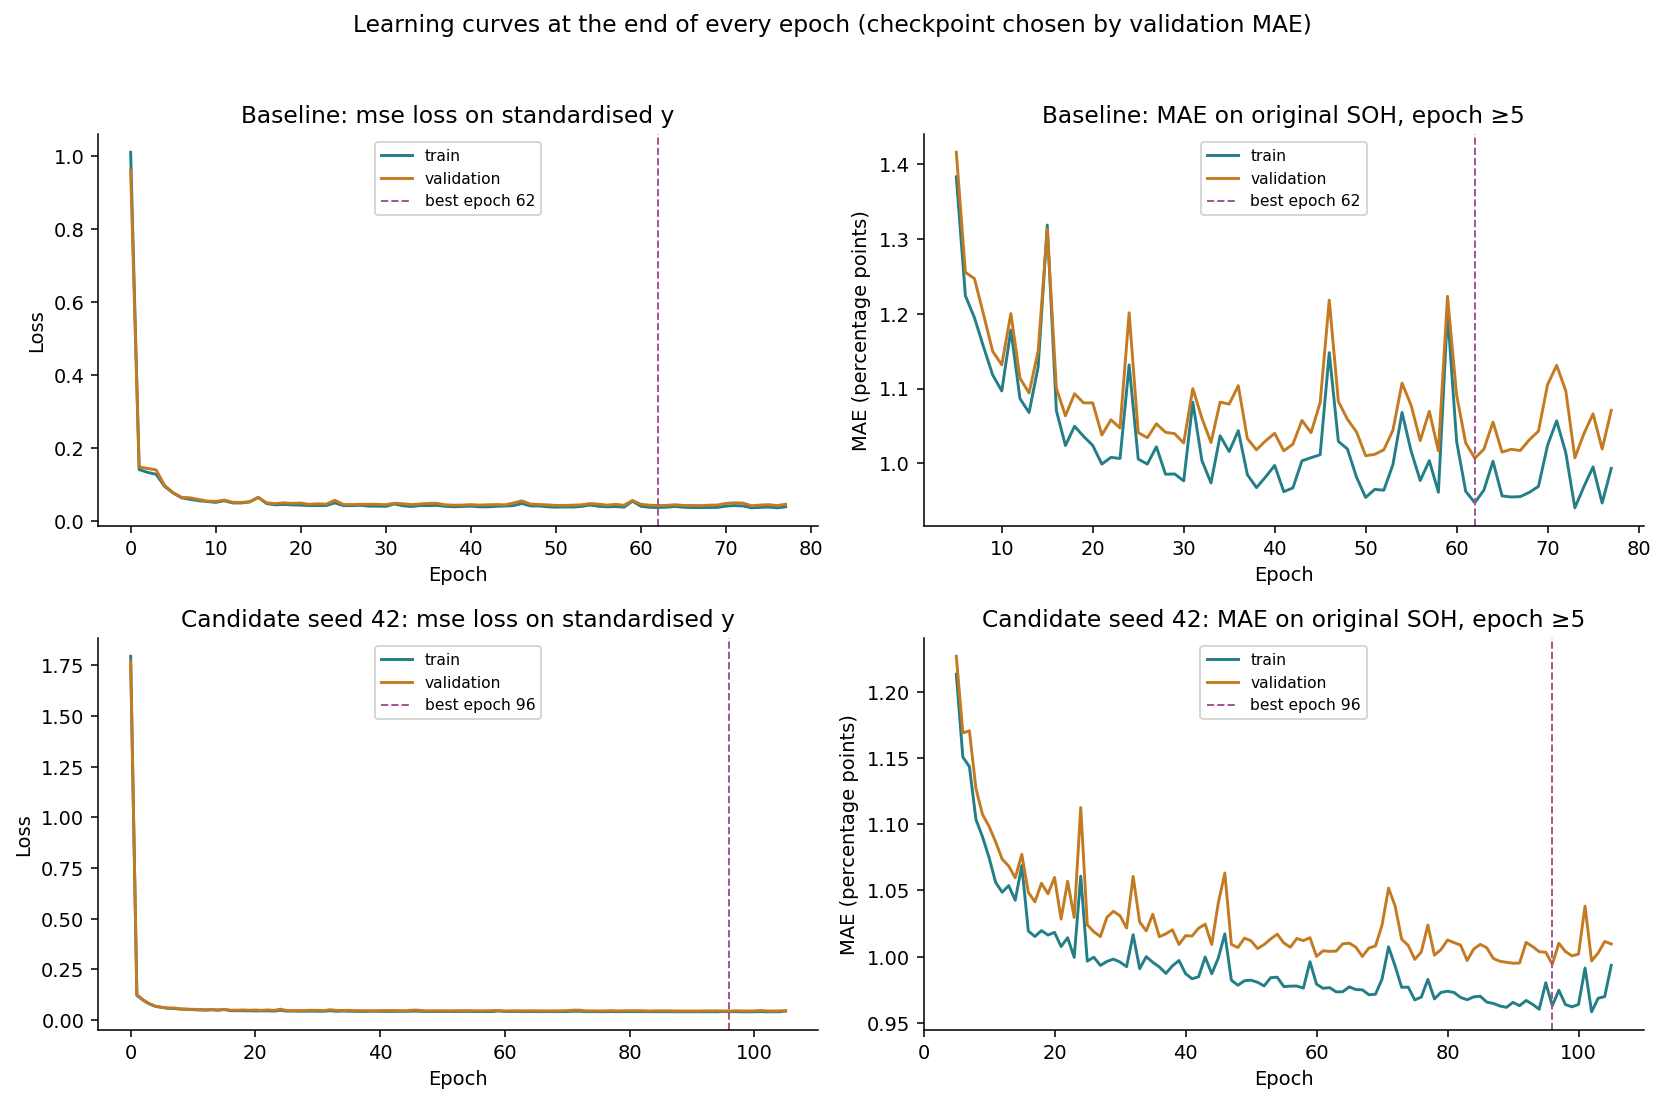

In [12]:
baseline = summaries[study["baseline_run_id"]]
candidate = summaries[study["candidate_run_id"]]
comparison = pd.DataFrame(
    [
        {
            "model": label,
            "layer_conf": run["layer_conf"],
            "parameters": run["parameters"],
            "best_epoch": run["best_epoch"],
            "epochs_actual": run["epochs_actual"],
            "train_MAE": run["train"]["mae"],
            "validation_MAE": run["validation"]["mae"],
            "gradien_awal": run["first_batch_gradient_l2_norm"],
        }
        for label, run in [("baseline", baseline), ("kandidat", candidate)]
    ]
)
display(comparison.round(4))
show("01_learning_curves.png")

**Temuan:** loss train dan validation turun tajam di awal training, lalu mendatar. Gradien batch pertama tidak nol, jadi backpropagation berjalan. Baseline mencapai validation MAE sekitar 1,007 poin SOH dengan checkpoint terbaik di epoch 62, lalu early stopping menghentikan training di epoch 77.

## 7. Checkpoint dan early stopping

- **`best.npz`** menyimpan bobot dengan validation MAE terendah.
- **`last.npz`** menyimpan bobot di epoch terakhir.
- Early stopping menghentikan training jika validation MAE tidak membaik lebih dari 0,001 poin selama 15 epoch.

Sel berikut memuat ulang `best.npz` dan memastikan validation MAE-nya sama persis dengan yang tercatat.

In [13]:
model, checkpoint = load_checkpoint(ROOT / baseline["checkpoint_best"], baseline_data)
pred_soh = original_scale(model.predict(baseline_data["validation"]["X"]), baseline_data["bundle"])
recomputed = regression_metrics(baseline_data["validation"]["y_original"], pred_soh)
assert np.isclose(recomputed["mae"], baseline["validation"]["mae"], atol=1e-12)
print(
    "layer_conf:",
    model.layer_conf,
    "| epoch checkpoint:",
    checkpoint["epoch"],
    "| MAE:",
    round(recomputed["mae"], 4),
)

layer_conf: (67, 32, 1) | epoch checkpoint: 62 | MAE: 1.0068


## 8. Perbandingan per tahap

,stage,recipe,hidden_layers,activation,loss,optimizer,learning_rate,sample_weighting,max_error,validation_mae_pp,train_mae_pp,epochs_actual,selected
0,preprocessing,baseline_standard,32,sigmoid,mse,gd,0.100,none,0.00,1.0068,0.9473,77,True
1,preprocessing,baseline_minmax,32,sigmoid,mse,gd,0.100,none,0.00,1.0129,0.9567,135,False
2,preprocessing,log_sensor_caps,32,sigmoid,mse,gd,0.100,none,0.00,1.0077,0.9605,65,False
3,preprocessing,compact_log_sensor_caps,32,sigmoid,mse,gd,0.100,none,0.00,1.0137,0.9714,67,False
4,hidden_layers,baseline_standard,2,sigmoid,mse,gd,0.100,none,0.00,1.0892,1.0888,54,False
5,hidden_layers,baseline_standard,8,sigmoid,mse,gd,0.100,none,0.00,0.9943,0.9629,105,True
6,hidden_layers,baseline_standard,32,sigmoid,mse,gd,0.100,none,0.00,1.0068,0.9473,77,False
7,hidden_layers,baseline_standard,64,sigmoid,mse,gd,0.100,none,0.00,0.9950,0.9491,65,False
8,hidden_layers,baseline_standard,64-32,sigmoid,mse,gd,0.100,none,0.00,0.9960,0.9380,77,False
9,hidden_layers,baseline_standard,128-64-32,sigmoid,mse,gd,0.100,none,0.00,0.9966,0.9495,77,False


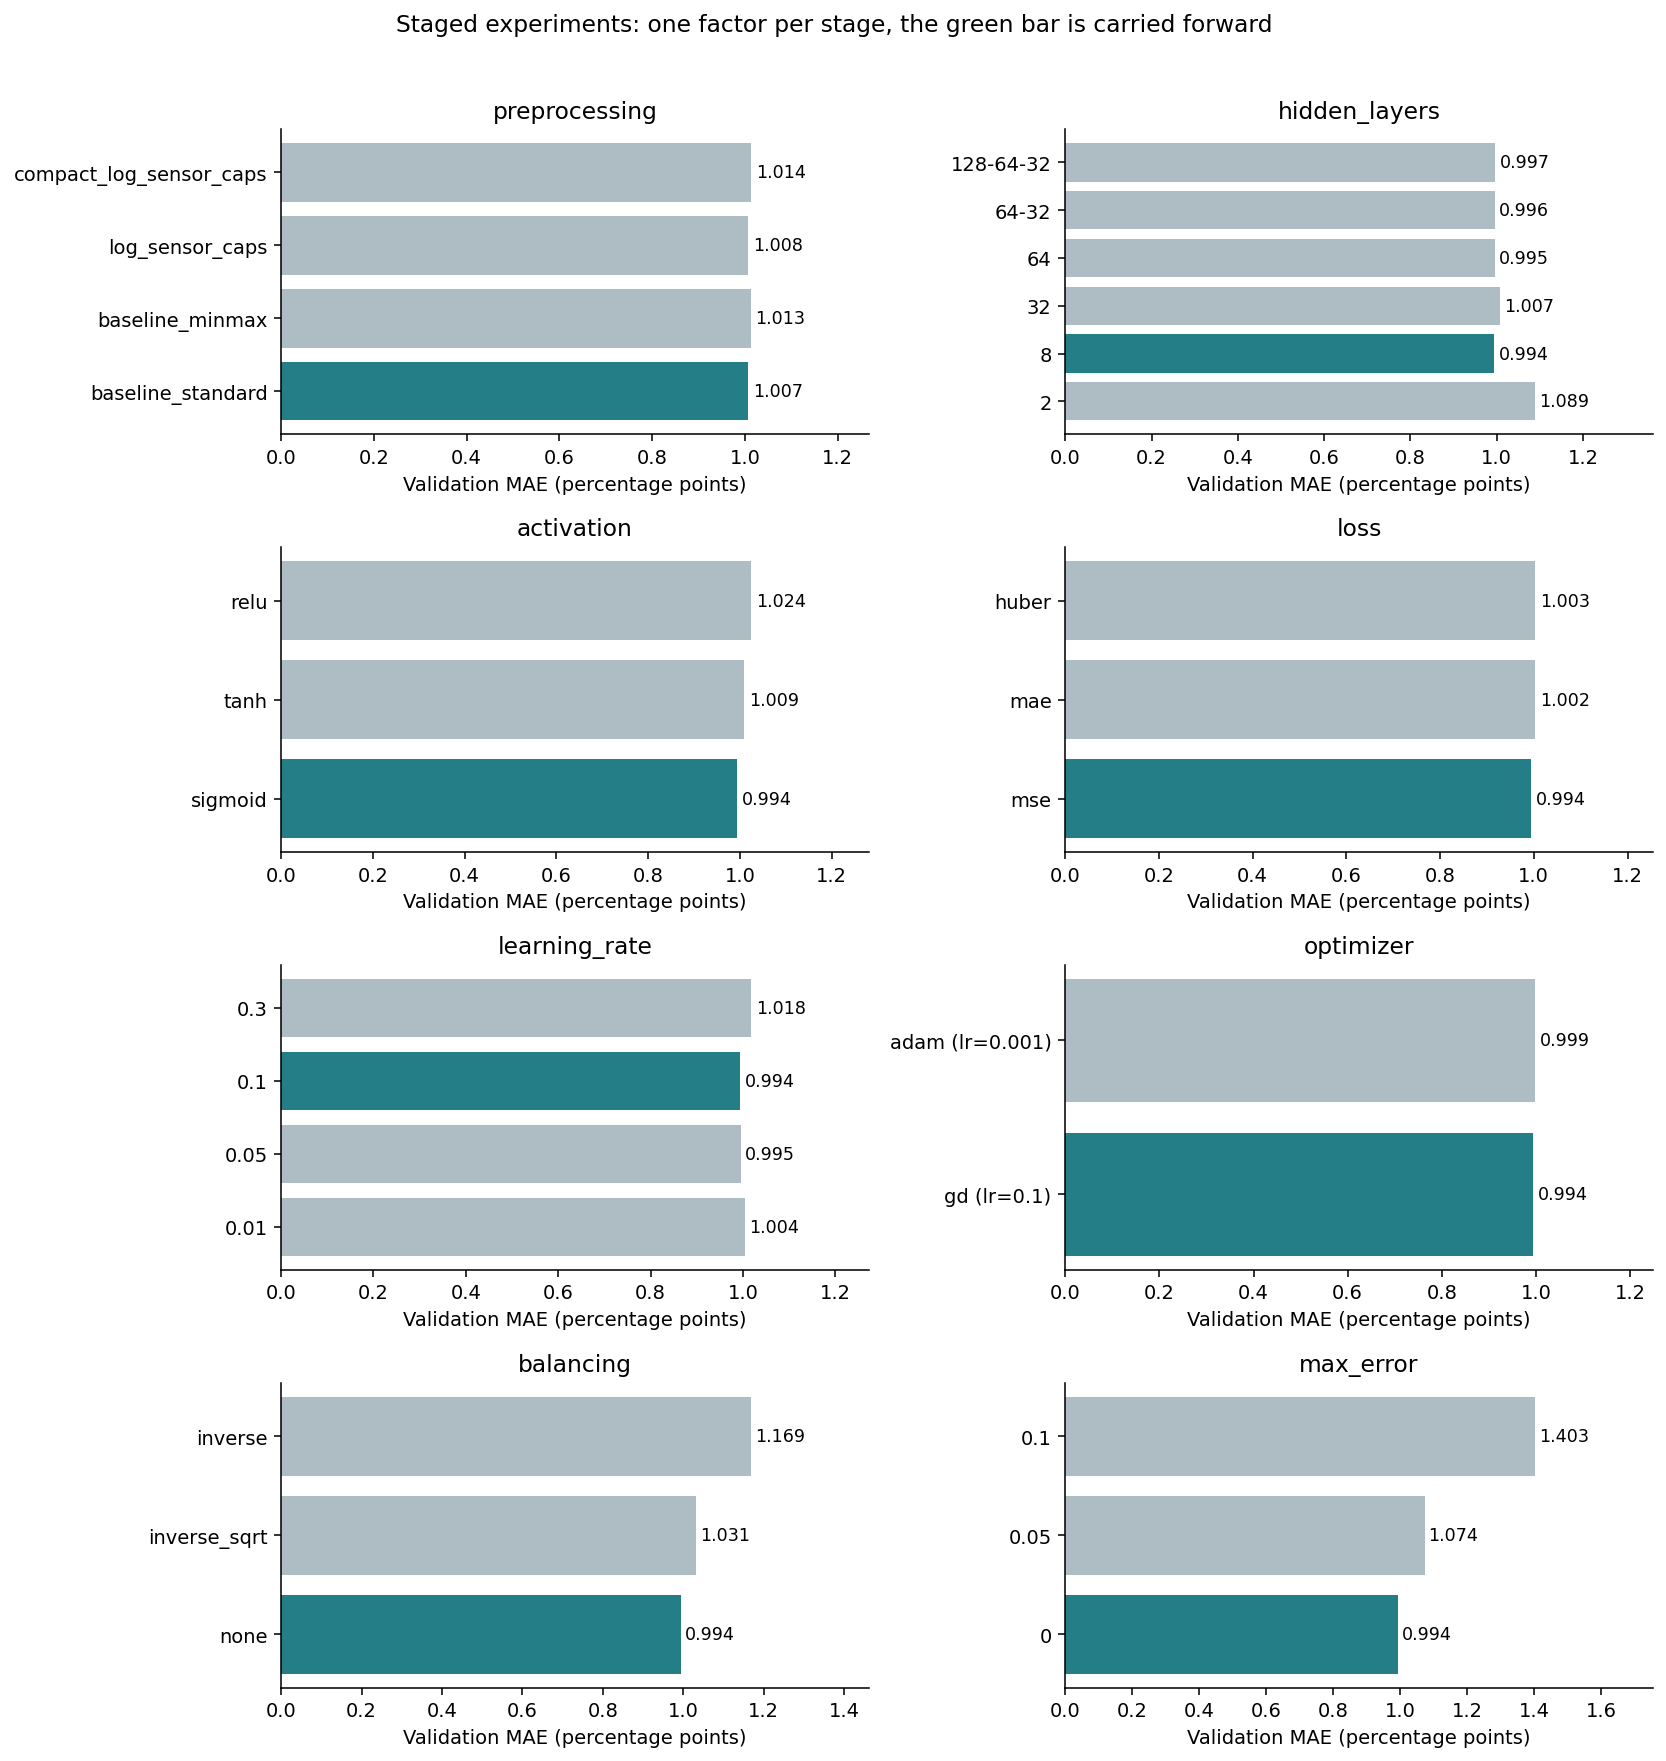

In [14]:
display(
    stages[
        [
            "stage",
            "recipe",
            "hidden_layers",
            "activation",
            "loss",
            "optimizer",
            "learning_rate",
            "sample_weighting",
            "max_error",
            "validation_mae_pp",
            "train_mae_pp",
            "epochs_actual",
            "selected",
        ]
    ].round(4)
)
show("02_stage_comparisons.png")

**Interpretasi per faktor:**

- **Input neuron (resep preprocessing):** keempat resep berada dalam rentang 1,007 sampai 1,014. Standardisasi (`baseline_standard`) sedikit lebih baik dari min-max (1,013). Log transform, capping, dan membuang 2 fitur redundan (63 input) tidak memberi perbaikan.
- **Hidden layer:** 2 neuron jelas underfitting (1,089). Mulai 8 neuron hasilnya mendatar di sekitar 0,994 sampai 0,997. Jaringan yang lebih dalam ([64, 32], [128, 64, 32]) tidak lebih baik dan butuh waktu hingga 4 kali lebih lama.
- **Activation function:** sigmoid (0,994) lebih baik dari tanh (1,009) dan ReLU (1,024) pada konfigurasi ini.
- **Loss function:** MSE (0,994) sedikit lebih baik dari MAE (1,003) dan Huber (1,003). MAE loss berhenti sangat cepat (epoch 27) karena gradiennya hanya bernilai -1 atau +1.
- **Learning rate:** 0,01 terlalu lambat (butuh 189 epoch), 0,3 terlalu besar sehingga hasilnya lebih buruk (1,018). Nilai 0,05 sampai 0,1 paling stabil.

Selisih antarkonfigurasi umumnya kecil (sekitar 0,01 poin SOH), jadi perlu dicek apakah stabil di seed lain (bagian 13).

## 9. Gradient descent vs Adam

,optimizer,learning_rate,validation_mae_pp,train_mae_pp,best_epoch,epochs_actual,seconds
20,gd,0.100,0.9943,0.9629,96,105,9.0420
21,adam,0.001,0.9985,0.9544,39,42,4.4158


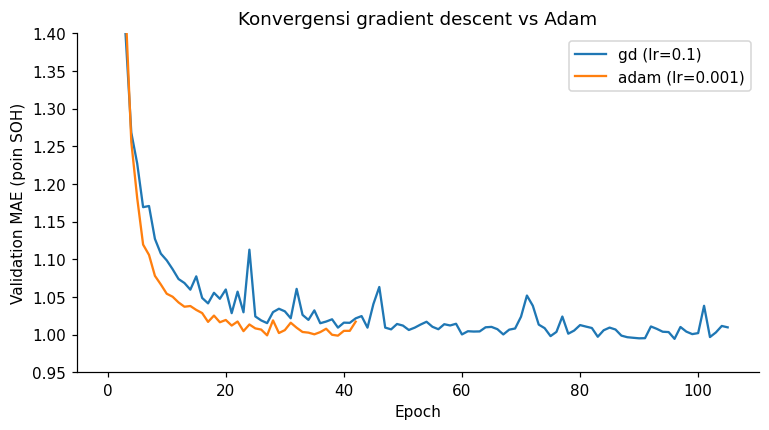

In [15]:
optimizer_rows = stages[stages.stage.eq("optimizer")]
display(
    optimizer_rows[
        [
            "optimizer",
            "learning_rate",
            "validation_mae_pp",
            "train_mae_pp",
            "best_epoch",
            "epochs_actual",
            "seconds",
        ]
    ].round(4)
)
import io

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for row in optimizer_rows.itertuples():
    history = histories[row.run_id]
    ax.plot(history.epoch, history.validation_mae_pp, label=f"{row.optimizer} (lr={row.learning_rate:g})")
ax.set(
    xlabel="Epoch",
    ylabel="Validation MAE (poin SOH)",
    ylim=(0.95, 1.4),
    title="Konvergensi gradient descent vs Adam",
)
ax.legend()
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(Image(data=buffer.getvalue()))

**Interpretasi:** Adam mencapai titik terbaiknya lebih cepat (epoch 39) dibanding gradient descent (epoch 96), karena langkah belajar setiap bobot menyesuaikan diri. Namun validation MAE akhirnya sedikit lebih buruk (0,999 vs 0,994). Untuk jaringan kecil ini, gradient descent biasa seperti di modul sudah cukup.

## 10. Balancing dengan bobot per rentang SOH

Karena target kontinu, balancing kelas biasa tidak berlaku. Padanannya untuk regresi adalah memberi **bobot sampel** yang lebih besar pada rentang SOH yang jarang (misalnya di bawah 70%), sehingga kontribusinya ke loss lebih besar. Bobot dihitung dari train saja.

- `inverse`: bobot = 1 / frekuensi rentang (setiap rentang berkontribusi sama).
- `inverse_sqrt`: versi yang lebih lunak, 1 / akar frekuensi.

Bobot mentah `inverse` mempunyai total sama per rentang pada seluruh train. Setiap mini-batch membagi gradien dengan jumlah bobotnya sendiri sehingga kontribusi efektif ikut bergantung pada komposisi batch.

,sample_weighting,soh_band,rows,batteries,mae_pp
0,none,<70,106,28,3.6015
1,none,70–<80,338,80,2.1118
2,none,80–<90,1390,218,1.3309
3,none,90–<95,1814,305,0.9797
4,none,>=95,3851,384,0.7098
5,inverse_sqrt,<70,106,28,3.3613
6,inverse_sqrt,70–<80,338,80,2.1282
7,inverse_sqrt,80–<90,1390,218,1.3814
8,inverse_sqrt,90–<95,1814,305,0.9894
9,inverse_sqrt,>=95,3851,384,0.7629


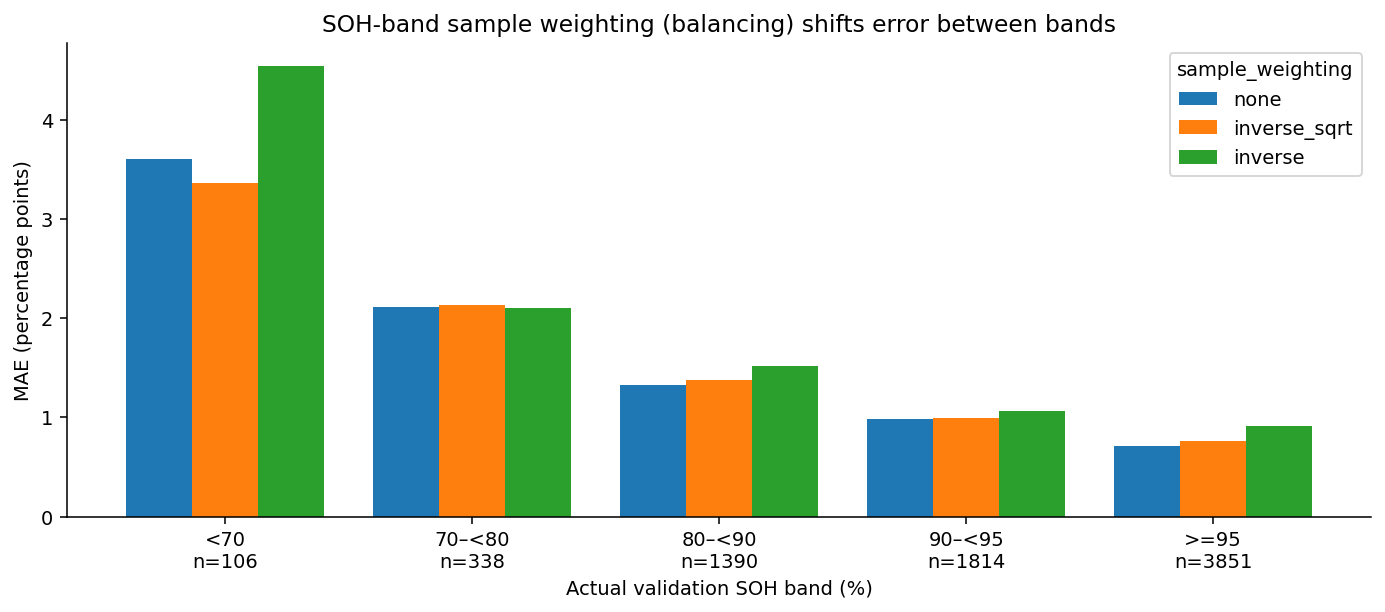

In [16]:
display(tables["balancing_validation_bands"].round(4))
show("08_balancing_by_band.png", 900)

**Interpretasi:** `inverse_sqrt` menurunkan error pada SOH di bawah 70% (3,60 menjadi 3,36 poin), tetapi menaikkan error di rentang lain sehingga MAE keseluruhan memburuk (1,031). `inverse` terlalu agresif: bobot yang sangat besar membuat training tidak stabil, dan error justru naik di hampir semua rentang. Balancing adalah trade-off: memperbaiki kelompok minoritas dengan mengorbankan mayoritas. Karena kriteria seleksi adalah MAE keseluruhan, model utama tidak memakai bobot.

Bobot mentah `inverse` mempunyai total sama per rentang pada seluruh train. Setiap mini-batch membagi gradien dengan jumlah bobotnya sendiri sehingga kontribusi efektif ikut bergantung pada komposisi batch.

## 11. `max_error` dan jumlah epoch

Seperti di modul, `max_error` menghentikan training saat MSE epoch (pada target terstandar) sudah di bawah nilai tersebut.

,max_error,validation_mae_pp,train_mae_pp,epochs_actual,stop_reason
25,0.00,0.9943,0.9629,105,early_stopping
26,0.05,1.0737,1.0487,12,max_error
27,0.10,1.4028,1.3743,3,max_error


,epoch,train_mae,validation_mae,validation_rmse,validation_r2
0,50,0.9822,1.0119,1.5298,0.9525
1,100,0.9638,1.0019,1.5176,0.9533
2,200,0.9596,1.0029,1.4954,0.9546


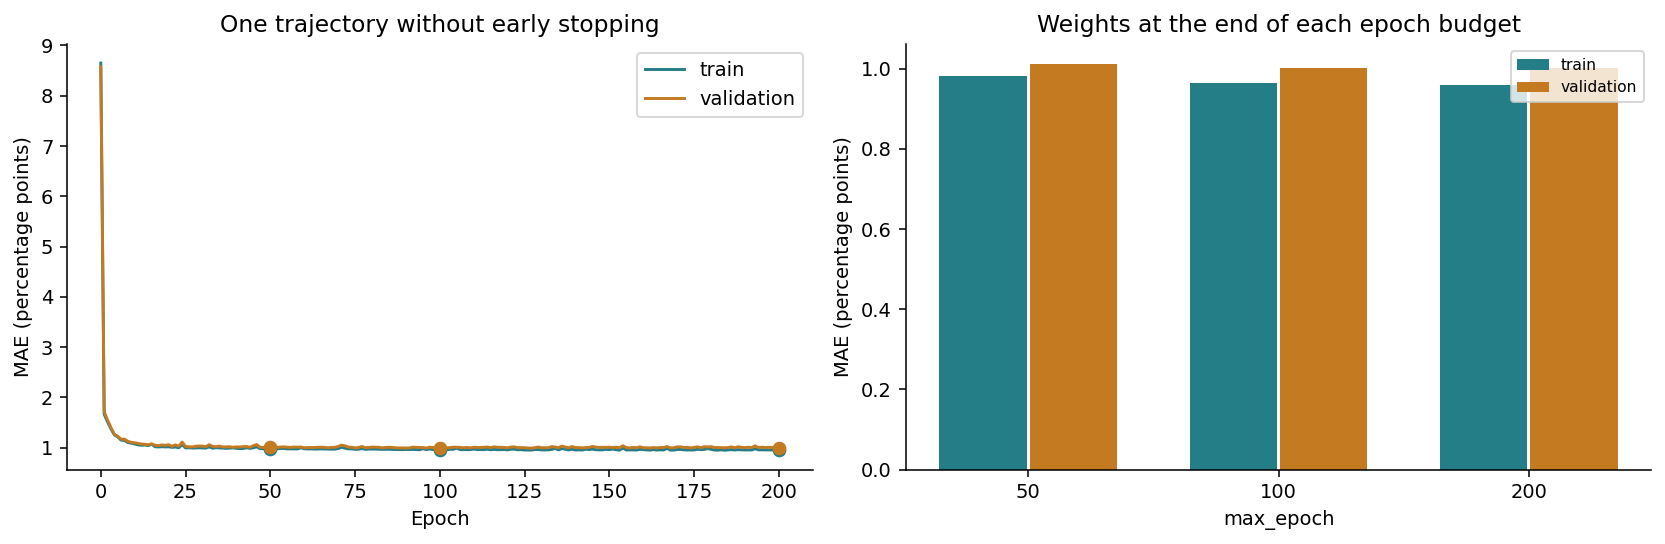

In [17]:
display(
    stages[stages.stage.eq("max_error")][
        ["max_error", "validation_mae_pp", "train_mae_pp", "epochs_actual", "stop_reason"]
    ].round(4)
)
display(
    tables["epoch_budget_comparison"][
        ["epoch", "train_mae", "validation_mae", "validation_rmse", "validation_r2"]
    ].round(4)
)
show("04_epoch_budget.png")

**Interpretasi:**

- `max_error` 0,05 menghentikan training di epoch 12 dan 0,1 di epoch 3. Keduanya underfitting (validation MAE 1,074 dan 1,403). Batas error yang terlalu longgar membuat model berhenti belajar terlalu cepat.
- Eksperimen epoch (tanpa early stopping): validation MAE 1,012 di epoch 50, 1,002 di epoch 100, dan 1,003 di epoch 200, sementara train MAE terus turun. Setelah sekitar 100 epoch, tambahan epoch tidak lagi memperbaiki validation.

## 12. Underfitting vs overfitting (seperti LC 7)

Dua konfigurasi sengaja dibuat ekstrem:

- **Underfitting:** hidden 2 neuron, `max_epoch` 50, `max_error` 0,5.
- **Overfitting:** hidden 128 neuron, 1.000 epoch tanpa early stopping, tetapi hanya dilatih pada 100 baterai (sekitar 6% data train).

,scenario,run_id,hidden_layers,train_rows,max_epochs,max_error,epochs_actual,stop_reason,train_mae_pp,validation_mae_pp,gap_pp,final_train_mae_pp,final_validation_mae_pp,final_gap_pp
0,underfitting,run_990e876cb506,2,34929,50,0.5,1,max_error,1.5179,1.5465,0.0286,1.5179,1.5465,0.0286
1,overfitting,run_19e4fd829263,128,1963,1000,0.0,1000,max_epoch,0.7704,1.2468,0.4764,0.6173,1.3662,0.7489


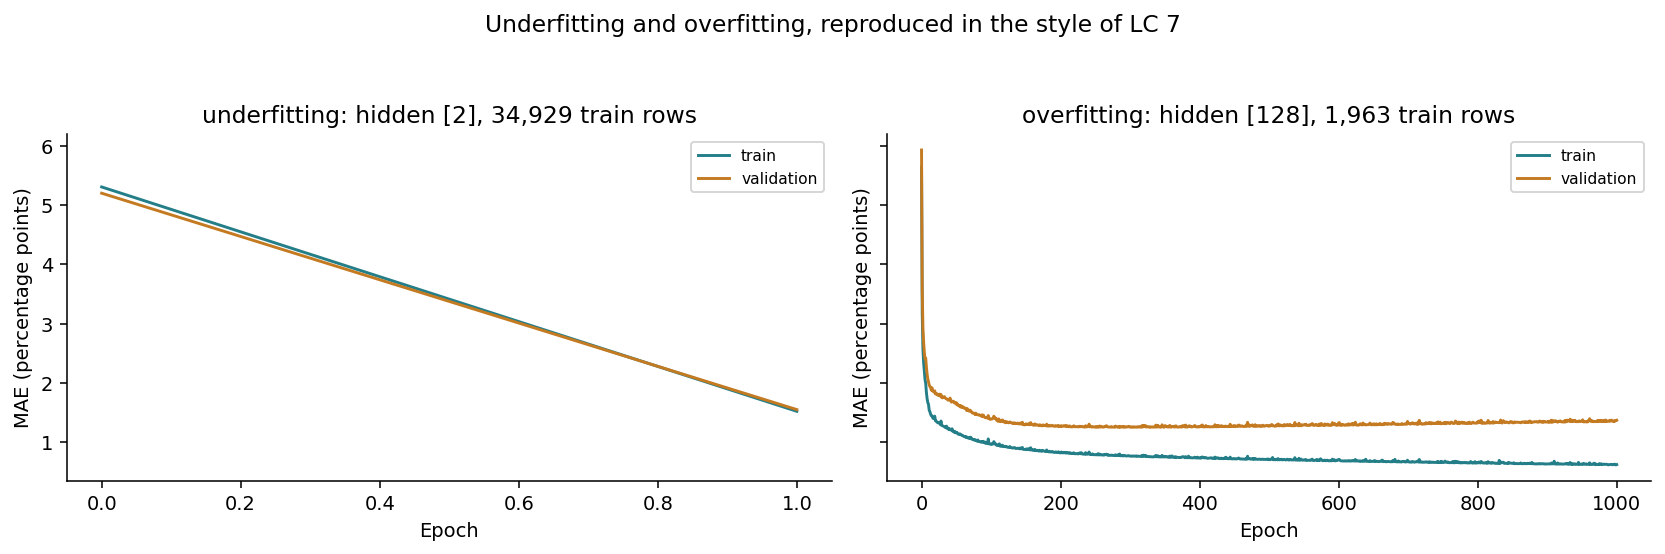

In [18]:
display(tables["capacity_demo"].round(4))
show("07_underfitting_overfitting.png")

**Interpretasi:**

- **Underfitting:** training berhenti setelah 1 epoch karena MSE sudah di bawah 0,5. Train MAE (1,52) dan validation MAE (1,55) sama-sama tinggi. Model terlalu kecil dan terlalu cepat berhenti.
- **Overfitting:** di akhir training, train MAE turun sampai 0,62 (lebih rendah dari model mana pun yang dilatih dengan seluruh data), tetapi validation MAE 1,37. Gap-nya 0,75 poin. Kurva menunjukkan validation terbaik di epoch 278, lalu memburuk sementara train terus membaik. Jaringan menghafal data train yang sedikit.

Study utama tidak mengalami overfitting kuat karena memakai 34.929 baris train dan early stopping.

## 13. Kandidat dan konfirmasi tiga seed

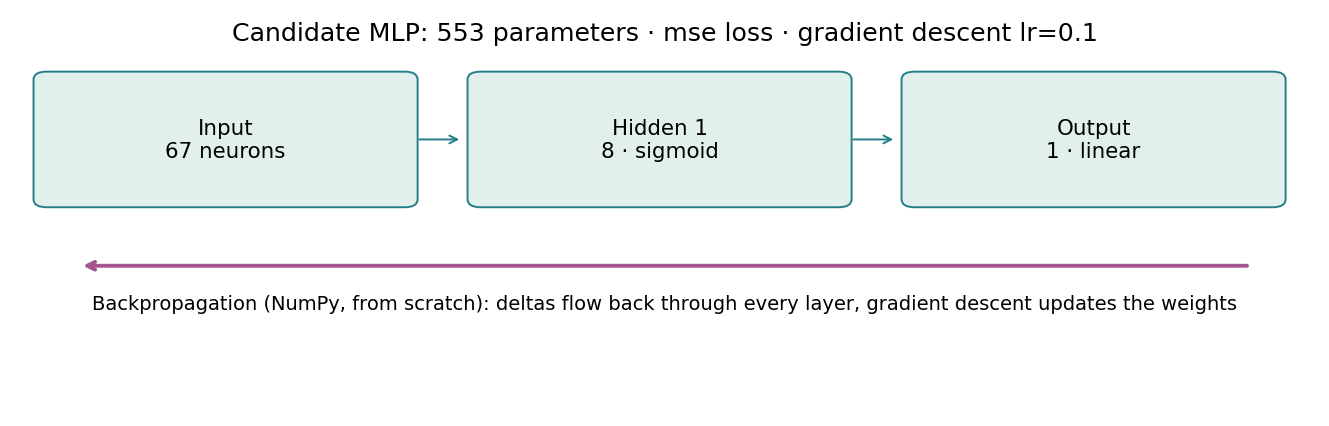

,group,seed,run_id,validation_mae_pp,validation_rmse_pp,validation_r2,train_mae_pp,best_epoch
0,baseline,42,run_cd4e6f80a183,1.0068,1.4866,0.9551,0.9473,62
1,baseline,123,run_96e0465b8c5f,0.9988,1.5041,0.9541,0.9601,41
2,baseline,2026,run_27c8116694bb,0.9943,1.4917,0.9548,0.9452,49
3,candidate,42,run_0015e8ebf51d,0.9943,1.5039,0.9541,0.9629,96
4,candidate,123,run_17e82e31806b,1.0094,1.5140,0.9535,0.9749,56
5,candidate,2026,run_125d105f67b2,0.9959,1.4920,0.9548,0.9705,58


,group,n_seeds,validation_mae_mean,validation_mae_std,validation_rmse_mean,validation_r2_mean
0,baseline,3,1.0000,0.0064,1.4941,0.9547
1,candidate,3,0.9999,0.0083,1.5033,0.9541


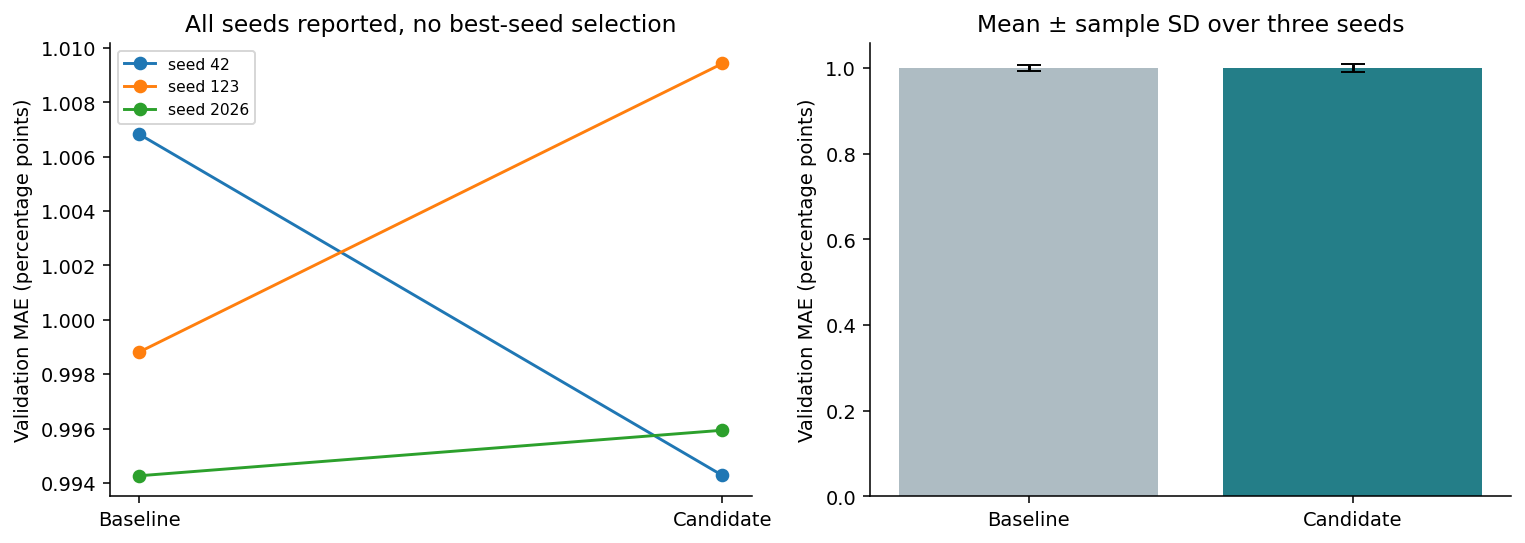

In [19]:
show("03_candidate_architecture.png")
display(tables["seed_confirmation"].round(4))
display(tables["seed_summary"].round(4))
show("05_seed_confirmation.png", 900)

**Kandidat:** resep `baseline_standard`, 67 input, hidden [8] dengan sigmoid, output linear, MSE loss, gradient descent dengan learning rate 0,1. Jumlah parameternya hanya 553, empat kali lebih kecil dari baseline (2.209).

**Temuan penting:** pada tiga seed, validation MAE rata-rata baseline **0,99997 ± 0,0064** dan kandidat **0,99988 ± 0,0083**. Keduanya praktis sama. Keunggulan kandidat pada seed 42 berada dalam batas variasi antar-seed, jadi pemilihan hidden [8] tidak terbukti memperbaiki akurasi. Kelebihan yang nyata adalah ukuran model yang jauh lebih kecil dengan akurasi setara.

## 14. Analisis error validation

Prediksi dikembalikan ke satuan SOH dan tidak dipotong ke rentang 0 sampai 100.

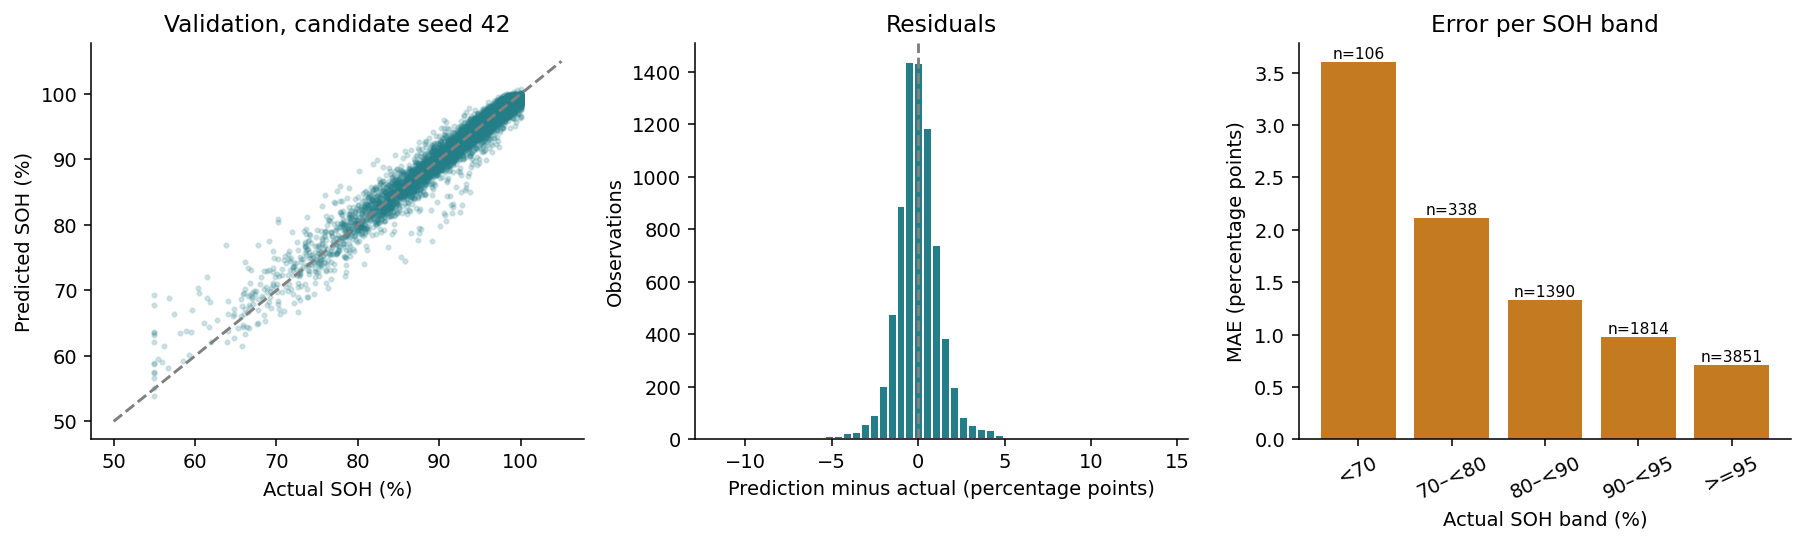

,soh_band,rows,batteries,mae_pp
0,<70,106,28,3.6015
1,70–<80,338,80,2.1118
2,80–<90,1390,218,1.3309
3,90–<95,1814,305,0.9797
4,>=95,3851,384,0.7098


MAE per baterai (rerata): 0.997
Prediksi di luar 0..100 (%): 0.24


In [20]:
show("06_validation_errors.png")
display(tables["candidate_validation_bands"].round(4))
print("MAE per baterai (rerata):", round(candidate["validation"]["battery_mean_mae"], 4))
print("Prediksi di luar 0..100 (%):", round(candidate["validation"]["outside_0_100_pct"], 3))
assert tables["candidate_validation_bands"].rows.sum() == 7499

**Temuan:** untuk SOH di bawah 70%, MAE sekitar **3,60 poin** (106 observasi, 28 baterai), sedangkan untuk SOH ≥95% hanya sekitar **0,71 poin**. Model jauh lebih akurat pada baterai sehat karena data train didominasi SOH tinggi.

## 15. Pembanding konstan dan gap overfitting

In [21]:
display(tables["constant_references"].round(4))
gaps = pd.DataFrame(
    [
        {
            "model": label,
            "train_MAE": run["train"]["mae"],
            "validation_MAE": run["validation"]["mae"],
            "gap": run["validation"]["mae"] - run["train"]["mae"],
        }
        for label, run in [("baseline", baseline), ("kandidat", candidate)]
    ]
)
display(gaps.round(4))

,reference,constant_soh,mae,rmse,r2,bias_pp,outside_0_100_pct,battery_mean_mae
0,train_median,95.2300,4.9432,7.3623,-0.1000,2.2199,0.0,4.9363
1,train_mean,92.9187,5.2697,7.0202,-0.0002,-0.0913,0.0,5.2737


,model,train_MAE,validation_MAE,gap
0,baseline,0.9473,1.0068,0.0596
1,kandidat,0.9629,0.9943,0.0314


**Interpretasi:** menebak median atau rerata train memberi MAE sekitar 4,9 sampai 5,3 poin, sedangkan MLP sekitar 1,0 poin. Gap validation dan train kecil (0,060 untuk baseline, 0,031 untuk kandidat), jadi model utama tidak overfitting.

## 16. Verifikasi

Unit test mencakup kesamaan dengan `bp_fit` modul, gradient check, contoh hitung manual, `max_error`, Adam, bobot balancing, checkpoint, dan larangan akses test. Sel terakhir memastikan hasil tersimpan konsisten dengan kode dan konfigurasi saat ini.

In [22]:
checked = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests"], cwd=REPO, capture_output=True, text=True
)
print(checked.stderr.strip().splitlines()[-1])
assert checked.returncode == 0

OK


In [23]:
assert study["source_sha256"] == training_source_sha256()
assert study["settings_sha256"] == hashlib.sha256((ROOT / "configs/mlp_study.json").read_bytes()).hexdigest()
assert study["test_loaded"] is False
for run_id, run in summaries.items():
    history = histories[run_id]
    assert history.epoch.tolist() == list(range(run["epochs_actual"] + 1))
    assert np.isclose(
        history.loc[history.epoch.gt(0), "validation_mae_pp"].min(), run["validation"]["mae"], atol=1e-9
    )
print("PASS: semua run konsisten dengan kode, konfigurasi, dan history-nya. Test tidak dimuat.")

PASS: semua run konsisten dengan kode, konfigurasi, dan history-nya. Test tidak dimuat.


## 17. Kesimpulan

| Faktor | Hasil (validation) |
|---|---|
| Input neuron | 67 dengan standardisasi, setara dengan min-max dan resep lain |
| Hidden layer | 2 neuron underfitting, 8 neuron sudah cukup, lebih besar tidak membantu |
| Activation function | sigmoid terbaik |
| Loss function | MSE terbaik |
| Learning rate | 0,05 sampai 0,1 paling stabil |
| Optimizer | gradient descent sedikit lebih akurat, Adam lebih cepat konvergen |
| Balancing | memperbaiki SOH rendah, tetapi memperburuk keseluruhan |
| `max_error` dan epoch | batas longgar menyebabkan underfitting, lebih dari 100 epoch tidak membantu |

Kandidat (67 → [8] sigmoid → 1) dan baseline (67 → [32] sigmoid → 1) setara pada tiga seed. Keduanya dievaluasi pada test di notebook 05.

Reproduksi dari root proyek:

```bash
python -m ev_battery train
python scripts/run_notebook.py notebooks/numpy/03_mlp_experiments.ipynb
```

**Berikutnya:** `04_feature_engineering.ipynb` menguji fitur turunan dengan kandidat ini sebagai kontrol.